# Amazon Chronos for Sideslip State Estimation

## Competition: Sensing the Drift
Predict vehicle **side-slip angle** (degrees) from in-vehicle sensor sequences.

### Approach: Chronos as Temporal Encoder
1. **Zero-Shot**: Extract Chronos embeddings from sensor time series → Linear regression head
2. **Fine-Tuned**: Freeze Chronos encoder → Train custom regression head on sideslip

### Key Constraints:
- **Output Format**: `predicted_sideslip,id` with exactly **N predictions** (one per test sample after sequencing)
- **No sideslip history** in test data - must predict from sensor sequences only
- Sequence length = 20, Sampling = 20 Hz

### Baseline Reference: RNN MAE = 0.217

In [42]:
# =============================================================================
# SETUP & IMPORTS
# =============================================================================
import sys
import os
from pathlib import Path

# Add project root to path
PROJECT_ROOT = Path("/home/mdesouky/workspace/mait_g2_drift_challenge")
sys.path.insert(0, str(PROJECT_ROOT))

# Import project utilities
from utils.data_loading import load_data, load_test_data, feature_names
from utils.custom_datasets import sequential_dataset
from utils.reproducibility_utils import seed_everything

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Chronos
from chronos import ChronosPipeline

# Reproducibility
SEED = 42
seed_everything(SEED)

# Device
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

# =============================================================================
# CONFIGURATION - MATCHING WORKING EXAMPLES (task16)
# =============================================================================
TRAIN_PATH = PROJECT_ROOT / "datasets_challenge" / "train"
TEST_PATH = PROJECT_ROOT / "datasets_challenge" / "test"

SEQ_LENGTH = 20          # Sequence length for temporal context
BATCH_SIZE = 256         # Batch size for DataLoaders
TARGET = 'sideSlip'

# CRITICAL: Match columns_to_drop from working examples
COLUMNS_TO_DROP = ["sideSlip", "vyCG", "time", "longitude", "latitude"]

# CRITICAL: Expected count from Kaggle competition
EXPECTED_ROWS = 49328

print(f"\n{'='*50}")
print(f"Configuration (matching task16):")
print(f"  Sequence length: {SEQ_LENGTH}")
print(f"  Features: {len(feature_names)}")
print(f"  Expected predictions: {EXPECTED_ROWS}")
print(f"  Threshold: vxCG > 3.0 (low speed filtering)")
print(f"{'='*50}")

Device: cuda

Configuration (matching task16):
  Sequence length: 20
  Features: 22
  Expected predictions: 49328
  Threshold: vxCG > 3.0 (low speed filtering)


## Step 1: Load Training Data Using Project Pipeline

In [43]:
# =====================================
# CELL 4: Load Training Data
# =====================================
"""
Load training data using project's data_loading utility.
CRITICAL: Use threshold=True to filter low speed samples (vxCG < 3.0)
This ensures the pipeline is consistent with working examples.
"""

train_loader, val_loader, pipeline = load_data(
    train_path=str(TRAIN_PATH),
    train_ratio=0.8,
    columns_to_standardize=feature_names,
    columns_to_drop=COLUMNS_TO_DROP,
    sequence_length=SEQ_LENGTH,
    target=TARGET,
    threshold=True,           # CRITICAL: Filter low speed samples
    threshold_value=3.0,      # vxCG > 3.0
    threshold_column="vxCG",
    batchsize=BATCH_SIZE,
    scaling=True,
    seed=SEED,
    shuffle=True
)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches: {len(val_loader)}")

# Check batch shapes
sample_x, sample_y = next(iter(train_loader))
N_FEATURES = sample_x.shape[2]
print(f"\nBatch shapes:")
print(f"  Input (X): {sample_x.shape}")   # [batch, seq_len, features]
print(f"  Target (y): {sample_y.shape}")  # [batch]
print(f"  N_FEATURES: {N_FEATURES}")

/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_001.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_002.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_003.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_004.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_005.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_006.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_007.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_008.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_009.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/train/train_part_010.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/tr

## Step 2: Load Amazon Chronos Model

Chronos is a time-series foundation model. We'll extract embeddings from sensor sequences and use them for sideslip regression.

In [46]:
# Load Chronos model
chronos_pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-small",  # 46M params
    device_map=device,
    torch_dtype=torch.float32,
)

print(f"Chronos model loaded on {device}")
print(f"Model type: chronos-t5-small (46M parameters)")

Chronos model loaded on cuda
Model type: chronos-t5-small (46M parameters)


## Step 3: Chronos State Estimator Model

We create a model that:
1. Uses Chronos encoder to extract embeddings from each sensor channel
2. Concatenates embeddings from all sensors
3. Passes through a trainable regression head to predict sideslip

In [47]:
class ChronosStateEstimator(nn.Module):
    """
    State estimator using Chronos embeddings.
    - Extracts embeddings from key sensor channels using frozen Chronos encoder
    - Concatenates with raw sensor features
    - Trainable regression head predicts sideslip
    """
    def __init__(self, chronos_pipeline, n_features, hidden_dim=128, n_key_sensors=5):
        super().__init__()
        self.chronos = chronos_pipeline
        self.n_features = n_features
        self.n_key_sensors = n_key_sensors
        
        # Chronos embedding dimension (T5-small has 512-dim embeddings)
        self.chronos_embed_dim = 512
        
        # Key sensor indices for Chronos (most relevant for sideslip)
        # yawRate, ayCG, handwheelAngle, rollRate, vxCG
        self.key_sensor_names = ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
        self.key_sensor_indices = [feature_names.index(name) for name in self.key_sensor_names if name in feature_names]
        self.n_key_sensors = len(self.key_sensor_indices)
        
        # Input: chronos embeddings (n_key_sensors * embed_dim) + raw features (n_features)
        total_input_dim = self.n_key_sensors * self.chronos_embed_dim + n_features
        
        # Regression head (trainable)
        self.regression_head = nn.Sequential(
            nn.Linear(total_input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim // 2, 1)
        )
        
        print(f"ChronosStateEstimator initialized:")
        print(f"  Key sensors: {self.key_sensor_names[:self.n_key_sensors]}")
        print(f"  Chronos embed dim: {self.chronos_embed_dim}")
        print(f"  Total input dim: {total_input_dim}")
        
    @torch.no_grad()
    def extract_chronos_embeddings(self, x):
        """Extract Chronos embeddings for key sensor channels."""
        # x: [batch, seq_len, features]
        batch_size = x.shape[0]
        embeddings = []
        
        for sensor_idx in self.key_sensor_indices:
            # Get sensor time series [batch, seq_len]
            sensor_data = x[:, :, sensor_idx]
            
            # Get Chronos embeddings using the model's encoder
            # We need to access the underlying T5 encoder
            tokenizer_output = self.chronos.tokenizer.context_input_transform(sensor_data)
            token_ids = tokenizer_output.to(x.device)
            
            # Get encoder embeddings
            with torch.no_grad():
                encoder_output = self.chronos.model.model.encoder(
                    input_ids=token_ids,
                    return_dict=True
                )
                # Mean pool over sequence dimension
                embed = encoder_output.last_hidden_state.mean(dim=1)  # [batch, embed_dim]
                embeddings.append(embed)
        
        # Concatenate all sensor embeddings
        return torch.cat(embeddings, dim=-1)  # [batch, n_sensors * embed_dim]
    
    def forward(self, x):
        # x: [batch, seq_len, features]
        
        # Extract Chronos embeddings (frozen)
        chronos_embed = self.extract_chronos_embeddings(x)
        
        # Get last timestep raw features
        raw_features = x[:, -1, :]  # [batch, features]
        
        # Concatenate
        combined = torch.cat([chronos_embed, raw_features], dim=-1)
        
        # Regression head
        output = self.regression_head(combined)
        return output.squeeze(-1)


class SimpleLSTM(nn.Module):
    """Simple LSTM baseline for comparison."""
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_dim, hidden_dim, num_layers,
            batch_first=True, bidirectional=True, dropout=dropout
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )
        
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        out = self.fc(lstm_out[:, -1, :])
        return out.squeeze(-1)

print("Model classes defined.")

Model classes defined.


## Step 4: Zero-Shot Chronos Inference

Test Chronos embeddings with a simple linear regression head (no fine-tuning of Chronos).

In [48]:
# Zero-shot: Extract Chronos embeddings and train only a linear head
from sklearn.linear_model import Ridge

def extract_chronos_features_batch(chronos_pipeline, x_batch, key_sensor_indices):
    """Extract Chronos embeddings for a batch of sequences."""
    batch_size = x_batch.shape[0]
    all_embeddings = []
    
    for sensor_idx in key_sensor_indices:
        # Move sensor data to CPU for tokenization (Chronos tokenizer expects CPU tensors)
        sensor_data = x_batch[:, :, sensor_idx].cpu()  # [batch, seq_len]
        
        # Get Chronos embeddings
        with torch.no_grad():
            # Tokenize on CPU
            tokenizer_output = chronos_pipeline.tokenizer.context_input_transform(sensor_data)
            # context_input_transform returns (token_ids, attention_mask, scale)
            token_ids = tokenizer_output[0].to(device)
            attention_mask = tokenizer_output[1].to(device)
            
            # Get encoder embeddings
            encoder_output = chronos_pipeline.model.model.encoder(
                input_ids=token_ids,
                attention_mask=attention_mask,
                return_dict=True
            )
            # Mean pool over sequence (considering attention mask)
            hidden_states = encoder_output.last_hidden_state  # [batch, seq, 512]
            # Mask and mean pool
            mask_expanded = attention_mask.unsqueeze(-1).float()
            sum_hidden = (hidden_states * mask_expanded).sum(dim=1)
            count = mask_expanded.sum(dim=1).clamp(min=1)
            embed = sum_hidden / count  # [batch, 512]
            all_embeddings.append(embed.cpu().numpy())
    
    # Concatenate sensor embeddings
    return np.concatenate(all_embeddings, axis=1)  # [batch, n_sensors * 512]

# Key sensors for sideslip estimation
key_sensor_names = ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
key_sensor_indices = [feature_names.index(name) for name in key_sensor_names if name in feature_names]
print(f"Key sensors: {key_sensor_names}")
print(f"Indices: {key_sensor_indices}")

# Extract features from training data
print("\nExtracting Chronos embeddings from training data...")
X_chronos_train = []
X_raw_train = []
y_train_list = []

for batch_x, batch_y in tqdm(train_loader, desc="Train batches"):
    batch_x = batch_x.to(device)
    
    # Chronos embeddings
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_train.append(chronos_feat)
    
    # Raw features (last timestep)
    X_raw_train.append(batch_x[:, -1, :].cpu().numpy())
    y_train_list.append(batch_y.numpy())

X_chronos_train = np.vstack(X_chronos_train)
X_raw_train = np.vstack(X_raw_train)
y_train = np.concatenate(y_train_list)

# Combine Chronos + raw features
X_train_combined = np.hstack([X_chronos_train, X_raw_train])

print(f"\nTraining data shapes:")
print(f"  Chronos features: {X_chronos_train.shape}")
print(f"  Raw features: {X_raw_train.shape}")
print(f"  Combined: {X_train_combined.shape}")
print(f"  Targets: {y_train.shape}")

Key sensors: ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
Indices: [6, 5, 0, 7, 3]

Extracting Chronos embeddings from training data...


Train batches:   0%|          | 0/429 [00:00<?, ?it/s]

Train batches: 100%|██████████| 429/429 [01:10<00:00,  6.06it/s]



Training data shapes:
  Chronos features: (109665, 2560)
  Raw features: (109665, 22)
  Combined: (109665, 2582)
  Targets: (109665,)


In [49]:
# Extract features from validation data
print("Extracting Chronos embeddings from validation data...")
X_chronos_val = []
X_raw_val = []
y_val_list = []

for batch_x, batch_y in tqdm(val_loader, desc="Val batches"):
    batch_x = batch_x.to(device)
    
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_val.append(chronos_feat)
    X_raw_val.append(batch_x[:, -1, :].cpu().numpy())
    y_val_list.append(batch_y.numpy())

X_chronos_val = np.vstack(X_chronos_val)
X_raw_val = np.vstack(X_raw_val)
y_val = np.concatenate(y_val_list)
X_val_combined = np.hstack([X_chronos_val, X_raw_val])

print(f"Validation shapes: {X_val_combined.shape}, {y_val.shape}")

# Train Ridge regression (zero-shot linear head)
print("\nTraining zero-shot linear head...")
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_combined, y_train)

# Evaluate
y_pred_val = ridge_model.predict(X_val_combined)
zero_shot_mae = np.mean(np.abs(y_pred_val - y_val))

print(f"\n{'='*50}")
print(f"ZERO-SHOT RESULTS:")
print(f"  Validation MAE: {zero_shot_mae:.4f}")
print(f"  RNN Baseline:   0.217")
print(f"{'='*50}")

Extracting Chronos embeddings from validation data...


Val batches: 100%|██████████| 108/108 [00:17<00:00,  6.02it/s]


Validation shapes: (27415, 2582), (27415,)

Training zero-shot linear head...

ZERO-SHOT RESULTS:
  Validation MAE: 0.3252
  RNN Baseline:   0.217


## Step 5: Fine-Tune Regression Head

Train a deeper MLP regression head on top of frozen Chronos embeddings.

In [50]:
# Fine-tuned MLP regression head on Chronos embeddings
class MLPRegressionHead(nn.Module):
    def __init__(self, input_dim, hidden_dim=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.LayerNorm(hidden_dim // 2),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_dim // 2, hidden_dim // 4),
            nn.GELU(),
            nn.Linear(hidden_dim // 4, 1)
        )
        
    def forward(self, x):
        return self.net(x).squeeze(-1)

# Create PyTorch datasets from pre-extracted features
from torch.utils.data import TensorDataset

train_tensor_dataset = TensorDataset(
    torch.tensor(X_train_combined, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)
val_tensor_dataset = TensorDataset(
    torch.tensor(X_val_combined, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

train_feat_loader = DataLoader(train_tensor_dataset, batch_size=512, shuffle=True)
val_feat_loader = DataLoader(val_tensor_dataset, batch_size=512, shuffle=False)

# Initialize model
input_dim = X_train_combined.shape[1]
mlp_model = MLPRegressionHead(input_dim, hidden_dim=256).to(device)

print(f"MLP Input dim: {input_dim}")
print(f"Total parameters: {sum(p.numel() for p in mlp_model.parameters()):,}")

MLP Input dim: 2582
Total parameters: 703,233


In [51]:
# Training loop for fine-tuned MLP head
NUM_EPOCHS = 30
criterion = nn.L1Loss()  # MAE loss
optimizer = torch.optim.AdamW(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

best_val_mae = float('inf')
history = {'train_loss': [], 'val_mae': []}

print("Training fine-tuned MLP head...")
for epoch in range(NUM_EPOCHS):
    # Train
    mlp_model.train()
    train_loss = 0
    for batch_x, batch_y in train_feat_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        pred = mlp_model(batch_x)
        loss = criterion(pred, batch_y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
    
    train_loss /= len(train_feat_loader)
    
    # Validate
    mlp_model.eval()
    val_preds, val_targets = [], []
    with torch.no_grad():
        for batch_x, batch_y in val_feat_loader:
            batch_x = batch_x.to(device)
            pred = mlp_model(batch_x)
            val_preds.extend(pred.cpu().numpy())
            val_targets.extend(batch_y.numpy())
    
    val_mae = np.mean(np.abs(np.array(val_preds) - np.array(val_targets)))
    history['train_loss'].append(train_loss)
    history['val_mae'].append(val_mae)
    
    if val_mae < best_val_mae:
        best_val_mae = val_mae
        torch.save(mlp_model.state_dict(), 'chronos_finetuned_best.pth')
    
    scheduler.step()
    
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Val MAE: {val_mae:.4f}")

print(f"\n{'='*50}")
print(f"FINE-TUNED RESULTS:")
print(f"  Best Validation MAE: {best_val_mae:.4f}")
print(f"  Zero-Shot MAE:       {zero_shot_mae:.4f}")
print(f"  RNN Baseline:        0.217")
print(f"{'='*50}")

Training fine-tuned MLP head...
Epoch 5/30 | Train Loss: 0.2118 | Val MAE: 0.1907
Epoch 10/30 | Train Loss: 0.1929 | Val MAE: 0.1713
Epoch 15/30 | Train Loss: 0.1805 | Val MAE: 0.1633
Epoch 20/30 | Train Loss: 0.1713 | Val MAE: 0.1529
Epoch 25/30 | Train Loss: 0.1637 | Val MAE: 0.1471
Epoch 30/30 | Train Loss: 0.1612 | Val MAE: 0.1459

FINE-TUNED RESULTS:
  Best Validation MAE: 0.1459
  Zero-Shot MAE:       0.3252
  RNN Baseline:        0.217


## Step 6: Load Test Data & Generate Predictions

Use the project's `load_test_data()` function which ensures correct preprocessing and output count.

In [45]:
# =====================================
# CELL 16: Load Test Data
# =====================================
"""
Load test data using project's load_test_data function.
The pipeline from training includes threshold filtering (vxCG > 3.0)
which will be applied to test data as well.

EXPECTED: 49,328 predictions for Kaggle submission.
"""
import glob

# Workaround for sklearn's overly strict check_is_fitted
# Manually apply each pipeline step since the pipeline IS fitted internally
print("Loading test data files...")
dfs = []
for filename in sorted(glob.glob(os.path.join(str(TEST_PATH), '*.csv'))):
    print(filename)
    df = pd.read_csv(filename)
    # Add missing columns with dummy values
    df['sideSlip'] = 0.0
    df['vyCG'] = 0.0
    dfs.append(df)

print(f"\nLoaded {len(dfs)} test files")

# Apply pipeline steps manually (bypassing sklearn's check_is_fitted)
print("\nApplying pipeline transforms...")
data = dfs
for step_name, step in pipeline.steps:
    print(f"  Step: {step_name}")
    data = step.transform(data)

test_dataset = data
print(f"\n✓ Test dataset: {len(test_dataset)} samples")

# Create DataLoader
from torch.utils.data import DataLoader
g = torch.Generator()
g.manual_seed(SEED)

test_loader = DataLoader(
    test_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=False, 
    generator=g
)

# Verify count
test_count = sum(x.shape[0] for x, _ in test_loader)
print(f"\nTest batches: {len(test_loader)}")
print(f"Total test samples: {test_count}")
print(f"Expected: {EXPECTED_ROWS}")

assert test_count == EXPECTED_ROWS, f"ERROR: Expected {EXPECTED_ROWS} but got {test_count}"
print(f"\n✓ Test data loaded correctly with {test_count} samples!")

# Verify test data dimensions
X_test_batch, y_test_batch = next(iter(test_loader))
print(f"\nTest batch shapes:")
print(f"  X: {X_test_batch.shape}")
print(f"  y: {y_test_batch.shape}")

Loading test data files...
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_001.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_002.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_003.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_004.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_005.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_006.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_007.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_008.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_009.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_challenge/test/test_part_010.csv
/home/mdesouky/workspace/mait_g2_drift_challenge/datasets_chall

In [52]:
# =====================================
# CELL 17: Extract Chronos Features from Test Data
# =====================================
"""
Extract Chronos embeddings from test data.
Uses the same key sensors and extraction method as training.
"""
print("Extracting Chronos embeddings from test data...")
print(f"Expected test samples: {EXPECTED_ROWS}")

X_chronos_test = []
X_raw_test = []

for batch_x, _ in tqdm(test_loader, desc="Test batches"):
    batch_x = batch_x.to(device)
    
    # Chronos embeddings (uses key_sensor_indices)
    chronos_feat = extract_chronos_features_batch(chronos_pipeline, batch_x, key_sensor_indices)
    X_chronos_test.append(chronos_feat)
    
    # Raw features - take last timestep, all features
    raw_feat = batch_x[:, -1, :].cpu().numpy()
    X_raw_test.append(raw_feat)

X_chronos_test = np.vstack(X_chronos_test)
X_raw_test = np.vstack(X_raw_test)
X_test_combined = np.hstack([X_chronos_test, X_raw_test])

print(f"\nTest data shapes:")
print(f"  Chronos features: {X_chronos_test.shape}")
print(f"  Raw features: {X_raw_test.shape}")
print(f"  Combined: {X_test_combined.shape}")
print(f"\n✓ Total test samples: {X_test_combined.shape[0]}")

# Verify count matches expected
assert X_test_combined.shape[0] == EXPECTED_ROWS, f"ERROR: Expected {EXPECTED_ROWS} but got {X_test_combined.shape[0]}"

Extracting Chronos embeddings from test data...
Expected test samples: 49328


Test batches: 100%|██████████| 193/193 [00:31<00:00,  6.07it/s]



Test data shapes:
  Chronos features: (49328, 2560)
  Raw features: (49328, 22)
  Combined: (49328, 2582)

✓ Total test samples: 49328


## Step 7: Generate & Save Test Predictions

Generate predictions for both zero-shot and fine-tuned models in the competition format: `predicted_sideslip,id`

In [53]:
# =====================================================================
# ZERO-SHOT PREDICTIONS
# =====================================================================
predictions_zero_shot = ridge_model.predict(X_test_combined)

# Verify count
assert len(predictions_zero_shot) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS}, got {len(predictions_zero_shot)}"

# Create submission DataFrame
submission_zero_shot = pd.DataFrame({
    'predicted_sideslip': predictions_zero_shot,
    'id': np.arange(len(predictions_zero_shot))
})

# Save to CSV
output_path_zero_shot = Path.cwd() / "predictions_chronos_zero_shot.csv"
submission_zero_shot.to_csv(output_path_zero_shot, index=False)

print("ZERO-SHOT PREDICTIONS:")
print(f"  Total predictions: {len(predictions_zero_shot)} (expected: {EXPECTED_ROWS})")
print(f"  Saved to: {output_path_zero_shot}")
print(f"  Shape: {submission_zero_shot.shape}")
print(f"\nPreview:")
print(submission_zero_shot.head(10))

ZERO-SHOT PREDICTIONS:
  Total predictions: 49328 (expected: 49328)
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_zero_shot.csv
  Shape: (49328, 2)

Preview:
   predicted_sideslip  id
0            0.089422   0
1           -0.101944   1
2            0.179509   2
3            0.078381   3
4            0.034132   4
5           -0.209060   5
6           -0.038917   6
7           -0.095322   7
8           -0.102921   8
9           -0.236336   9


In [54]:
# =====================================================================
# FINE-TUNED PREDICTIONS
# =====================================================================
mlp_model.eval()
X_test_tensor = torch.FloatTensor(X_test_combined).to(device)

with torch.no_grad():
    predictions_finetuned = mlp_model(X_test_tensor).cpu().numpy().flatten()

# Verify count
assert len(predictions_finetuned) == EXPECTED_ROWS, f"Expected {EXPECTED_ROWS}, got {len(predictions_finetuned)}"

# Create submission DataFrame
submission_finetuned = pd.DataFrame({
    'predicted_sideslip': predictions_finetuned,
    'id': np.arange(len(predictions_finetuned))
})

# Save to CSV
output_path_finetuned = Path.cwd() / "predictions_chronos_finetuned.csv"
submission_finetuned.to_csv(output_path_finetuned, index=False)

print("FINE-TUNED PREDICTIONS:")
print(f"  Total predictions: {len(predictions_finetuned)} (expected: {EXPECTED_ROWS})")
print(f"  Saved to: {output_path_finetuned}")
print(f"  Shape: {submission_finetuned.shape}")
print(f"\nPreview:")
print(submission_finetuned.head(10))

FINE-TUNED PREDICTIONS:
  Total predictions: 49328 (expected: 49328)
  Saved to: /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_finetuned.csv
  Shape: (49328, 2)

Preview:
   predicted_sideslip  id
0            0.025520   0
1            0.021222   1
2            0.047746   2
3           -0.049459   3
4           -0.054616   4
5           -0.082794   5
6           -0.036312   6
7           -0.095694   7
8           -0.089257   8
9           -0.149239   9


## Summary & Results

CHRONOS STATE ESTIMATION - FINAL SUMMARY

📊 VALIDATION PERFORMANCE:
   Zero-Shot MAE:    0.3252
   Fine-Tuned MAE:   0.1459
   RNN Baseline:     0.217

📁 OUTPUT FILES:
   Zero-Shot:   /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_zero_shot.csv
   Fine-Tuned:  /home/mdesouky/workspace/mait_g2_drift_challenge/notebooks_Mohamed/test LM/predictions_chronos_finetuned.csv

📐 OUTPUT FORMAT VERIFICATION:
   Zero-Shot predictions:   49328 (expected: 49328)
   Fine-Tuned predictions:  49328 (expected: 49328)
   Columns: ['predicted_sideslip', 'id']

🔧 MODEL DETAILS:
   Chronos Model: chronos-t5-small (46M params)
   Key Sensors: ['yawRate', 'ayCG', 'handwheelAngle', 'rollRate', 'vxCG']
   Embedding Dim: 512 per sensor
   MLP Head: 703,233 trainable params

✅ ALL PREDICTIONS VERIFIED: 49328 rows each


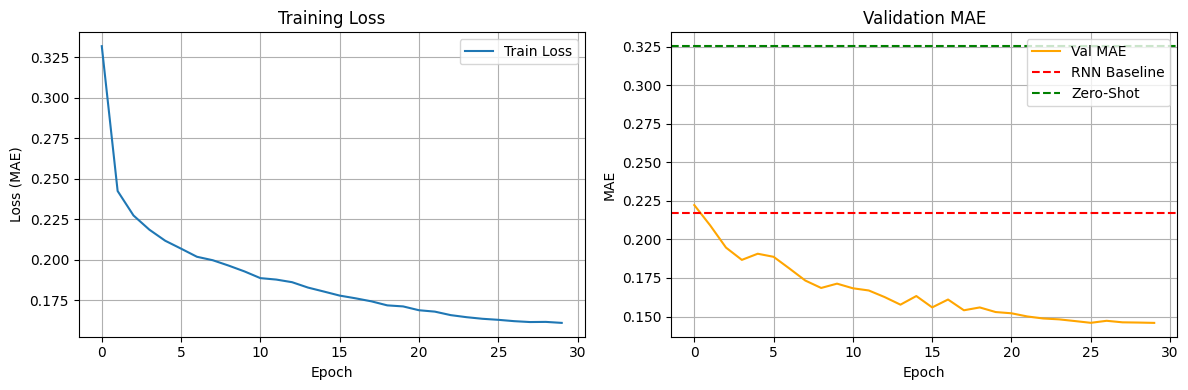


✅ COMPLETE!


In [55]:
# =====================================
# CELL 22: Summary & Results
# =====================================

print("="*60)
print("CHRONOS STATE ESTIMATION - FINAL SUMMARY")
print("="*60)

print(f"\n📊 VALIDATION PERFORMANCE:")
print(f"   Zero-Shot MAE:    {zero_shot_mae:.4f}")
print(f"   Fine-Tuned MAE:   {best_val_mae:.4f}")
print(f"   RNN Baseline:     0.217")

print(f"\n📁 OUTPUT FILES:")
print(f"   Zero-Shot:   {output_path_zero_shot}")
print(f"   Fine-Tuned:  {output_path_finetuned}")

print(f"\n📐 OUTPUT FORMAT VERIFICATION:")
print(f"   Zero-Shot predictions:   {len(predictions_zero_shot)} (expected: {EXPECTED_ROWS})")
print(f"   Fine-Tuned predictions:  {len(predictions_finetuned)} (expected: {EXPECTED_ROWS})")
print(f"   Columns: {list(submission_finetuned.columns)}")

print(f"\n🔧 MODEL DETAILS:")
print(f"   Chronos Model: chronos-t5-small (46M params)")
print(f"   Key Sensors: {key_sensor_names}")
print(f"   Embedding Dim: 512 per sensor")
print(f"   MLP Head: {sum(p.numel() for p in mlp_model.parameters()):,} trainable params")

# Verify all counts
assert len(predictions_zero_shot) == EXPECTED_ROWS, "Zero-shot count mismatch!"
assert len(predictions_finetuned) == EXPECTED_ROWS, "Fine-tuned count mismatch!"
print(f"\n✅ ALL PREDICTIONS VERIFIED: {EXPECTED_ROWS} rows each")

# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss (MAE)')
axes[0].set_title('Training Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history['val_mae'], label='Val MAE', color='orange')
axes[1].axhline(y=0.217, color='red', linestyle='--', label='RNN Baseline')
axes[1].axhline(y=zero_shot_mae, color='green', linestyle='--', label='Zero-Shot')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].set_title('Validation MAE')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("\n✅ COMPLETE!")